# Lab3 – NLP
-Read *War and Peace* (`pg2600.txt`) with Spark → remove punctuation & numbers → tokenise, lemmatise and stem with Spark NLP → WordCloud.

## Imports & Spark session

In [1]:
import os
os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
import sparknlp
from sparknlp.base import *
from sparknlp.annotator import *
from pyspark.ml import Pipeline
from pyspark.sql import functions as F

import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

spark = sparknlp.start(memory="8G")
print("Spark:", spark.version, "| Spark NLP:", sparknlp.version())

26/11/10 16:09:26 WARN Utils: Your hostname, MacBook-Air.local resolves to a loopback address: 127.0.0.1; using 192.168.0.143 instead (on interface en0)
26/11/10 16:09:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/Users/hadassah/cps4982/.venv/lib/python3.13/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/hadassah/.ivy2/cache
The jars for the packages stored in: /Users/hadassah/.ivy2/jars
com.johnsnowlabs.nlp#spark-nlp_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-fa36f0d4-58c5-4ad9-a85e-3f87953f9dc5;1.0
	confs: [default]
	found com.johnsnowlabs.nlp#spark-nlp_2.12;6.1.5 in central
	found com.typesafe#config;1.4.2 in central
	found org.rocksdb#rocksdbjni;6.29.5 in central
	found com.amazonaws#aws-java-sdk-s3;1.12.500 in central
	found com.amazonaws#aws-java-sdk-kms;1.12.500 in central
	found com.amazonaws#aws-java-sdk-core;1.12.500 in central
	found commons-logging#commons-logging;1.1.3 in central
	found commons-codec#commons-codec;1.15 in central
	found org.apache.httpcomponents#httpclient;4.5.13 in local-m2-cache
	found org.apache.httpcomponents#httpcore;4.4.13 in central
	found software.amazon.ion#ion-java;1.0.2 in central
	found joda-time#joda-time;2.8.1 in central
	found com.amazonaws#jmespath-java;1.12.

Spark: 3.5.7 | Spark NLP: 6.1.5


## 1. Read the book with Spark
The Project Gutenberg licence header/footer is dropped so only the novel itself is analysed.

In [2]:
raw = spark.read.text("pg2600.txt")
print("Total lines:", raw.count())

idx = raw.rdd.zipWithIndex()
start = idx.filter(lambda x: "*** START OF THE PROJECT GUTENBERG" in x[0].value).first()[1]
end   = idx.filter(lambda x: "*** END OF THE PROJECT GUTENBERG"   in x[0].value).first()[1]

book = idx.filter(lambda x: start < x[1] < end).map(lambda x: (x[0].value,)).toDF(["value"])
print("Book lines (header/footer removed):", book.count())
book.show(10, truncate=False)

Total lines: 66041


Book lines (header/footer removed): 65660


Exception ignored in: <_io.BufferedWriter name=5>
Traceback (most recent call last):
  File "/Users/hadassah/cps4982/.venv/lib/python3.13/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 193, in manager
BrokenPipeError: [Errno 32] Broken pipe


+----------------------+
|value                 |
+----------------------+
|                      |
|                      |
|                      |
|                      |
|WAR AND PEACE         |
|                      |
|                      |
|By Leo Tolstoy/Tolstoi|
|                      |
|                      |
+----------------------+
only showing top 10 rows



## 2. Remove punctuation and numbers
Lower-case → drop apostrophes (`don't` → `dont`) → replace every non-letter (punctuation, digits, `_`) with a space → collapse spaces. `\p{L}` keeps accented letters such as *Natásha*.

In [3]:
clean = (book
    .withColumn("text", F.lower("value"))
    .withColumn("text", F.regexp_replace("text", "['’‘]", ""))
    .withColumn("text", F.regexp_replace("text", "[^\\p{L}\\s]", " "))
    .withColumn("text", F.trim(F.regexp_replace("text", "\\s+", " ")))
    .filter(F.col("text") != "")
    .select("text"))

print("Non-empty lines:", clean.count())
clean.show(10, truncate=False)

# sanity check: no digits or punctuation left
left = clean.select(F.explode(F.split("text", " ")).alias("w")).filter(F.col("w").rlike("[^\\p{L}]"))
print("Tokens still containing digits/punctuation:", left.count())

Non-empty lines: 51854
+----------------------+
|text                  |
+----------------------+
|war and peace         |
|by leo tolstoy tolstoi|
|contents              |
|book one              |
|chapter i             |
|chapter ii            |
|chapter iii           |
|chapter iv            |
|chapter v             |
|chapter vi            |
+----------------------+
only showing top 10 rows



Exception ignored in: <_io.BufferedWriter name=5>
Traceback (most recent call last):
  File "/Users/hadassah/cps4982/.venv/lib/python3.13/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 193, in manager
BrokenPipeError: [Errno 32] Broken pipe


Tokens still containing digits/punctuation: 0


## 3. Spark NLP pipeline: tokens → lemmatisation → stop-word removal → stemming
- `Tokenizer` splits text into tokens (min length 3)
- `LemmatizerModel` (pretrained `lemma_antbnc`) maps each token to its dictionary form (*was* → *be*, *armies* → *army*)
- `StopWordsCleaner` removes stop words **after** lemmatisation, so lemmas like *be*/*have* are caught
- `Stemmer` (Porter) cuts each lemma down to its stem (*happiness* → *happi*)

In [4]:
stop_words = set(StopWordsCleaner.loadDefaultStopWords("english")) | set(STOPWORDS) | {
    "say", "said", "one", "will", "would", "could", "also", "us", "now", "even", "though"}

document_assembler = DocumentAssembler().setInputCol("text").setOutputCol("document")

tokenizer = Tokenizer() \
    .setInputCols(["document"]).setOutputCol("token") \
    .setMinLength(3)

lemmatizer = LemmatizerModel.pretrained("lemma_antbnc", "en") \
    .setInputCols(["token"]).setOutputCol("lemma")

stopwords_cleaner = StopWordsCleaner() \
    .setInputCols(["lemma"]).setOutputCol("clean_lemma") \
    .setStopWords(sorted(stop_words)).setCaseSensitive(False)

stemmer = Stemmer() \
    .setInputCols(["clean_lemma"]).setOutputCol("stem")

pipeline = Pipeline(stages=[document_assembler, tokenizer, lemmatizer, stopwords_cleaner, stemmer])

result = pipeline.fit(clean).transform(clean).cache()
result.selectExpr("text", "token.result AS tokens", "clean_lemma.result AS lemmas", "stem.result AS stems") \
      .show(10, truncate=60)

lemma_antbnc download started this may take some time.
Approximate size to download 907.6 KB
[ | ]

26/11/10 16:10:46 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/11/10 16:10:46 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


lemma_antbnc download started this may take some time.
Approximate size to download 907.6 KB
[ / ]Download done! Loading the resource.
[OK!]


+----------------------+-----------------------+-----------------------+-----------------------+
|                  text|                 tokens|                 lemmas|                  stems|
+----------------------+-----------------------+-----------------------+-----------------------+
|         war and peace|      [war, and, peace]|           [war, peace]|            [war, peac]|
|by leo tolstoy tolstoi|[leo, tolstoy, tolstoi]|[leo, tolstoy, tolstoi]|[leo, tolstoi, tolstoi]|
|              contents|             [contents]|              [content]|              [content]|
|              book one|            [book, one]|                 [book]|                 [book]|
|             chapter i|              [chapter]|              [chapter]|              [chapter]|
|            chapter ii|              [chapter]|              [chapter]|              [chapter]|
|           chapter iii|         [chapter, iii]|         [chapter, iii]|         [chapter, iii]|
|            chapter iv|      

### Token → lemma → stem examples

In [5]:
pairs = (result
    .select(F.col("clean_lemma.result").alias("lemma"), F.col("stem.result").alias("stem"))
    .select(F.explode(F.arrays_zip("lemma", "stem")).alias("p"))
    .select("p.lemma", "p.stem")
    .filter(F.col("lemma") != F.col("stem"))
    .distinct())
pairs.show(20)

+------------+----------+
|       lemma|      stem|
+------------+----------+
|     womanly|   womanli|
|       noisy|     noisi|
|      animal|      anim|
|      flurry|    flurri|
| villeneuves| villeneuv|
|    jealousy|  jealousi|
| recognition|  recognit|
|      sickly|    sickli|
|      ripple|     rippl|
|thanksgiving| thanksgiv|
|  blockhouse| blockhous|
| forthcoming|  forthcom|
|    illusion|     illus|
|  sleepiness|    sleepi|
|      larrey|    larrei|
|    eminence|      emin|
|  arakchéevs| arakchéev|
|      embody|    embodi|
|   monastery| monasteri|
|  dreadfully|dreadfulli|
+------------+----------+
only showing top 20 rows



### Token counts

In [6]:
tokens = result.select(F.explode("token.result").alias("w"))
lemmas = result.select(F.explode("clean_lemma.result").alias("w"))
stems  = result.select(F.explode("stem.result").alias("w"))

for name, df in [("tokens", tokens), ("lemmas (no stop words)", lemmas), ("stems", stems)]:
    print(f"{name:<24} total = {df.count():>7,}   unique = {df.distinct().count():>6,}")

lemma_freq = lemmas.groupBy("w").count().orderBy(F.desc("count"))
stem_freq  = stems.groupBy("w").count().orderBy(F.desc("count"))

print("\nTop 20 lemmas"); lemma_freq.show(20)
print("Top 20 stems");    stem_freq.show(20)

tokens                   total = 457,874   unique = 17,665
lemmas (no stop words)   total = 258,710   unique = 12,337
stems                    total = 258,710   unique = 10,353

Top 20 lemmas
+--------+-----+
|       w|count|
+--------+-----+
|     man| 1959|
|  prince| 1934|
|  pierre| 1796|
|     see| 1674|
|    look| 1614|
|    come| 1583|
|    know| 1578|
|      go| 1366|
|   think| 1266|
|    take| 1220|
|  andrew| 1143|
|    face| 1111|
|    feel| 1110|
| natásha| 1098|
|    time| 1084|
|     ask|  990|
|    well|  970|
|   begin|  967|
|princess|  935|
|   leave|  924|
+--------+-----+
only showing top 20 rows

Top 20 stems
+--------+-----+
|       w|count|
+--------+-----+
|   pierr| 1963|
|     man| 1959|
|   princ| 1935|
|     see| 1674|
|    look| 1614|
|    come| 1585|
|    know| 1578|
|      go| 1368|
|   think| 1266|
|    take| 1220|
| natásha| 1213|
|    feel| 1178|
|  andrew| 1143|
|    face| 1111|
|    time| 1085|
|     ask|  990|
|    well|  970|
|   begin|  968|
|pri

## 4. WordCloud
Frequencies are counted in Spark; only the top 300 words are collected to the driver.

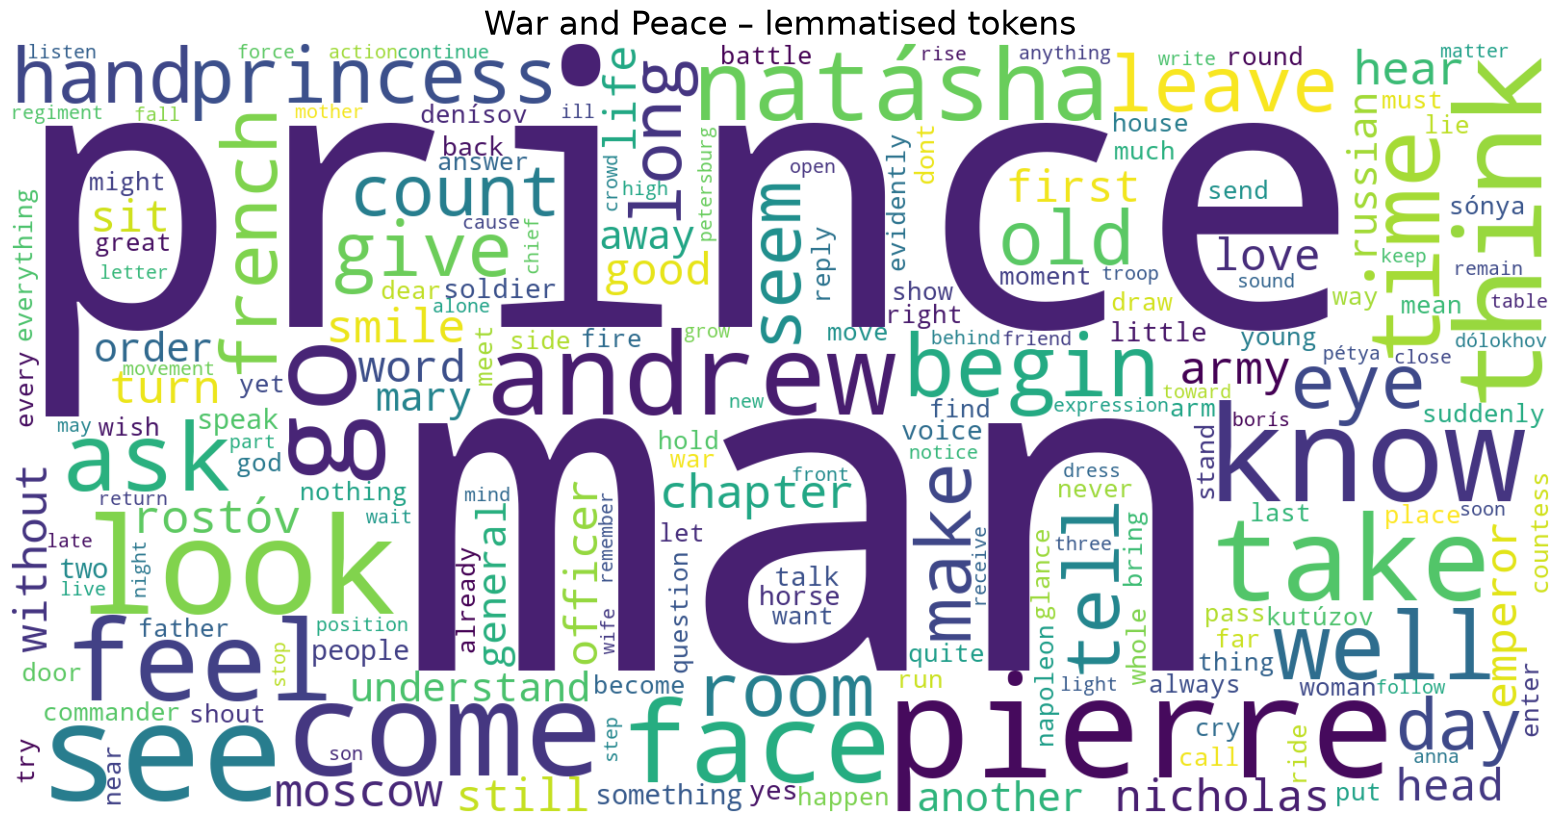

In [7]:
def show_cloud(freq_df, title, fname, n=300):
    freqs = {r["w"]: r["count"] for r in freq_df.limit(n).collect()}
    wc = WordCloud(width=1600, height=800, background_color="white",
                   colormap="viridis", random_state=42).generate_from_frequencies(freqs)
    wc.to_file(fname)
    plt.figure(figsize=(20, 10))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=24)
    plt.show()

show_cloud(lemma_freq, "War and Peace – lemmatised tokens", "wordcloud_lemma.png")

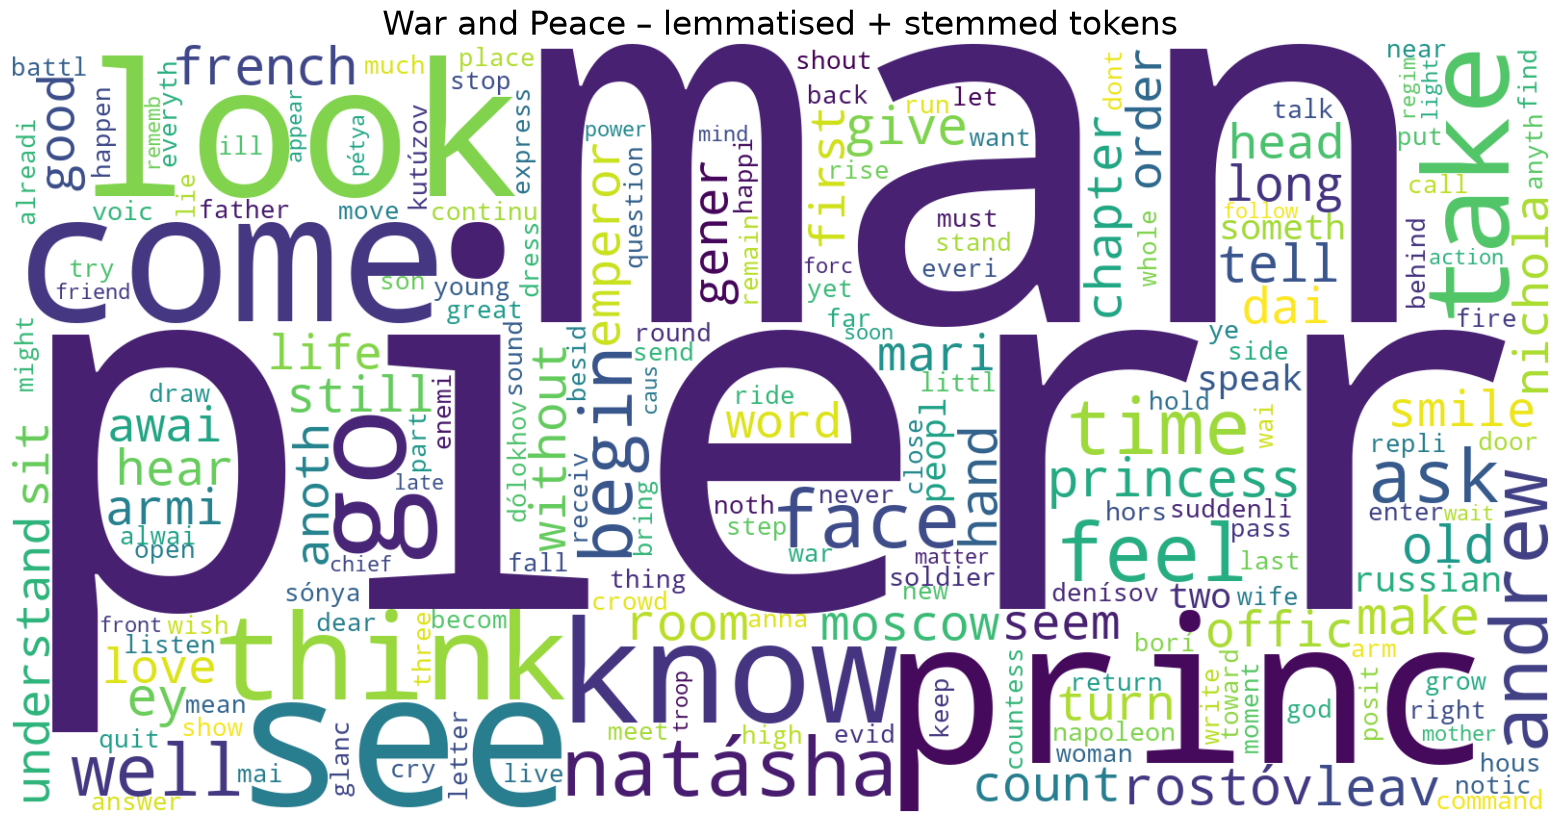

In [8]:
show_cloud(stem_freq, "War and Peace – lemmatised + stemmed tokens", "wordcloud_stem.png")

In [9]:
spark.stop()